Total Microplastic Particles Detected: 27
Mean Particle Area: 106.9 px² | Max Area: 331.5 px²


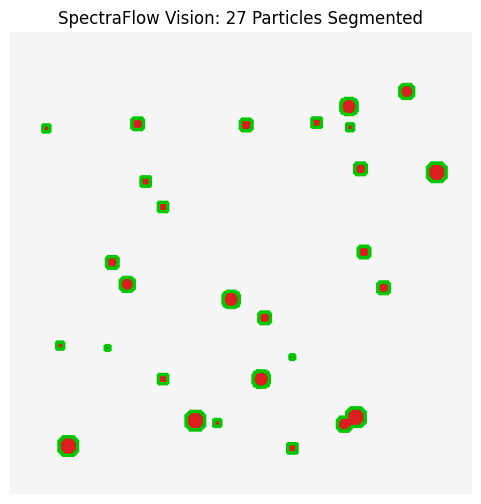

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate synthetic calibration image (white filter paper + colored microplastics)
img = np.ones((400, 400, 3), dtype=np.uint8) * 245
np.random.seed(42)
for _ in range(28):
    cx, cy = np.random.randint(30, 370, size=2)
    r = np.random.randint(3, 10)
    cv2.circle(img, (cx, cy), r, (30, 30, 220), -1)  # Red microplastic particles (BGR)

# 2. Convert to HSV color space and segment red plastic particles
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
mask1 = cv2.inRange(hsv, np.array([0, 100, 80]), np.array([10, 255, 255]))
mask2 = cv2.inRange(hsv, np.array([170, 100, 80]), np.array([180, 255, 255]))
mask = mask1 | mask2

# 3. Clean noise & extract particle contours
kernel = np.ones((3, 3), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

valid_particles = [c for c in contours if cv2.contourArea(c) > 10]
areas = [cv2.contourArea(c) for c in valid_particles]

print(f"Total Microplastic Particles Detected: {len(valid_particles)}")
print(f"Mean Particle Area: {np.mean(areas):.1f} px² | Max Area: {np.max(areas):.1f} px²")

# 4. Annotate and display output
output = img.copy()
cv2.drawContours(output, valid_particles, -1, (0, 200, 0), 2)
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"SpectraFlow Vision: {len(valid_particles)} Particles Segmented")
plt.axis('off')
plt.show()
